# Unsupervised Learning

## Aim

In this part of the project, we investigate whether benign and malignant
tumors can be separated using features extracted from digitized cell images
when the diagnosis labels are withheld from the models.

PCA is used to reduce the dimensionality of the dataset and examine the main
sources of variation. K-means and hierarchical clustering are then used to
investigate whether the observations naturally form groups that correspond
to the known benign and malignant diagnoses.

In [ ]:
#Data handling
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#Preprocessing and PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

#Clustering
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

#Evaluation
from sklearn.metrics import silhouette_score, adjusted_rand_score

Mounted at /content/drive


## Data preparation

The `id` column is removed because it is not a biological measurement. The diagnosis column is removed since that is what provides the true classes to model.

The remaining 30 numerical features are used for unsupervised analysis.

In [ ]:
#Load the dataset
df_data = pd.read_csv("data.csv")
#Remove columns that should not be used as features
X = df_data.drop(columns=["id", "diagnosis", "Unnamed: 32"])

#Check the dataset
print("Dataset dimensions:", X.shape)
print("Missing values:", X.isna().sum().sum())
print("Duplicate observations:", X.duplicated().sum())

display(X.head())

#Remove missing observations if there are any
X = X.dropna()

#Save diagnosis separately for later comparison
diagnosis = df_data.loc[X.index, "diagnosis"]


Dataset dimensions: (569, 30)
Missing values: 0
Duplicate observations: 0


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
#Standardize to mean 0 and std dev 1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## Principal Component Analysis

PCA is used to reduce the dimensionality of the dataset.  The explained variance shows how much information is retained by the principal components.

In [ ]:
#Apply PCA to all standardized features
pca = PCA()
X_pca = pca.fit_transform(X_scaled)
#Look at how much variation is explained by the components
print("PC1:", pca.explained_variance_ratio_[0])
print("PC2:", pca.explained_variance_ratio_[1])
print("First two PCs:", pca.explained_variance_ratio_[:2].sum())

print("First six PCs:")
print(pca.explained_variance_ratio_[:6].sum())

PC1: 0.44272025607526366
PC2: 0.18971182044033078
First two PCs: 0.6324320765155944
First six PCs:
0.887587963566906


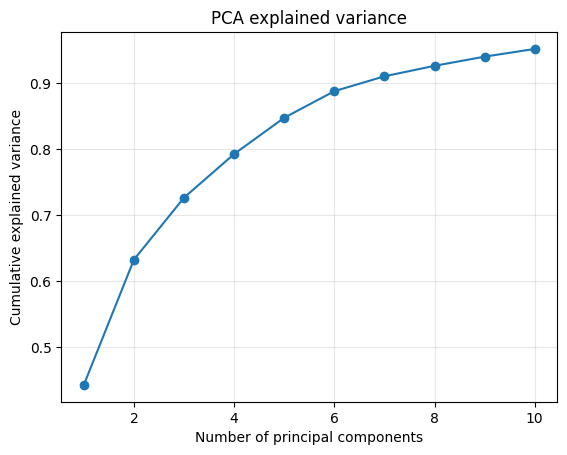

In [ ]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
#Plot the first 10 principal components
plt.plot(range(1, 11),cumulative_variance[:10],marker="o")

plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance")
plt.grid(alpha=0.3)
plt.show()

The first few principal components explain a large proportion of the variation in the dataset. This suggests that some of the information in the original 30 features can be represented using fewer dimensions.

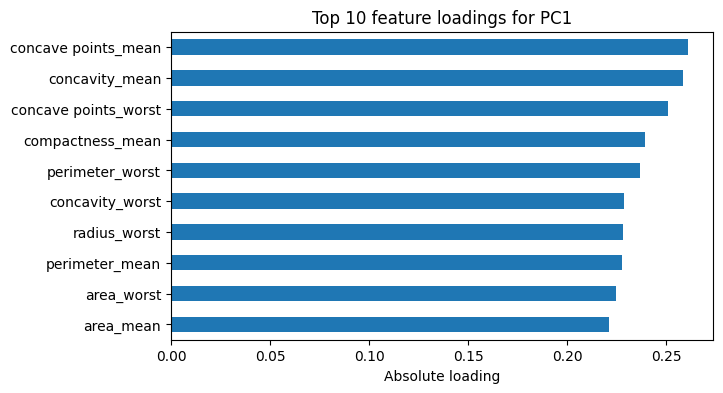

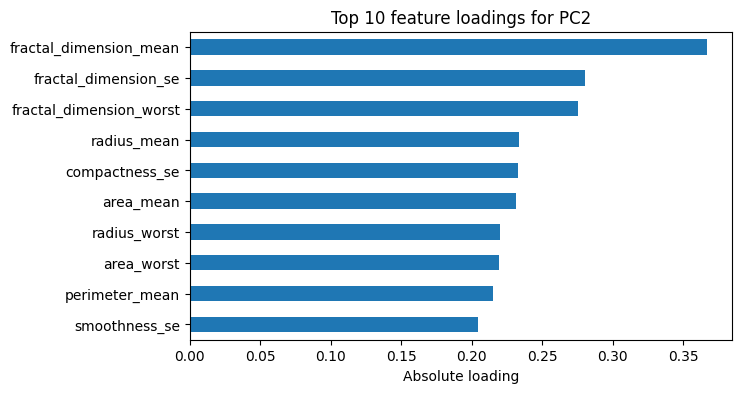

In [ ]:
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=[f"PC{i+1}" for i in range(pca.n_components_)])

for pc in ["PC1", "PC2"]:

    top_features = loadings[pc].abs().nlargest(10).sort_values()

    top_features.plot(kind="barh", figsize=(7, 4))

    plt.xlabel("Absolute loading")
    plt.title(f"Top 10 feature loadings for {pc}")
    plt.show()

The PCA loadings show which original features contribute most strongly to
PC1 and PC2, for PC1 this is dominated by concavity and for PC2 it is more size measurements.


## K-means clustering

K-means was used to test whether the observations form groups based
on their features.

Several values of `k` are compared using inertia and the silhouette score
before selecting the number of clusters for further analysis.


In [ ]:
kmeans_results = []

#Test k from 2 to 6
for k in range(2, 7):

  model = KMeans(n_clusters=k, random_state=123, n_init=10 )

  labels = model.fit_predict(X_scaled)

  kmeans_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels)})

kmeans_results = pd.DataFrame(kmeans_results)

display(kmeans_results)

,k,inertia,silhouette
0,2,11595.461474,0.344974
1,3,10061.797818,0.314384
2,4,9256.988836,0.279814
3,5,8554.941840,0.173058
4,6,7964.670760,0.161538


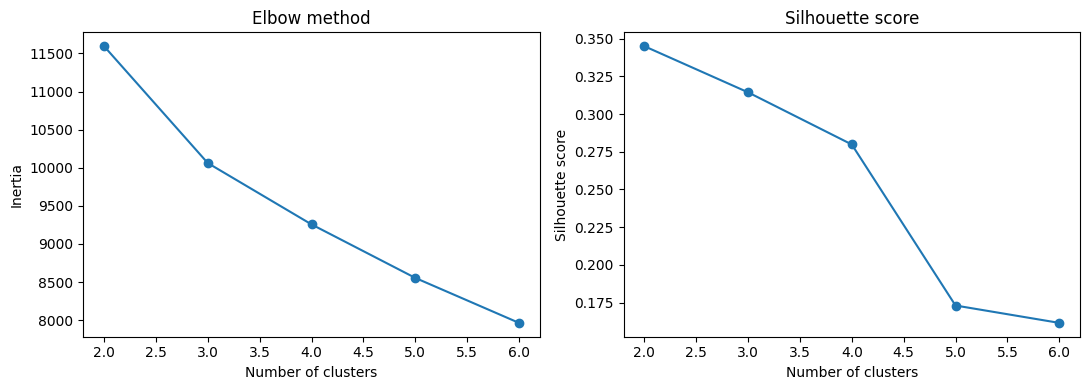

In [ ]:
#Compare inertia and silhouette score for different values of k
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    kmeans_results["k"],
    kmeans_results["inertia"],
    marker="o")

axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    kmeans_results["k"],
    kmeans_results["silhouette"],
    marker="o")

axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

Based on the results, two clusters were selected for further
analysis. This also allows the clustering result to be compared with the two
known diagnoses, benign and malignant.


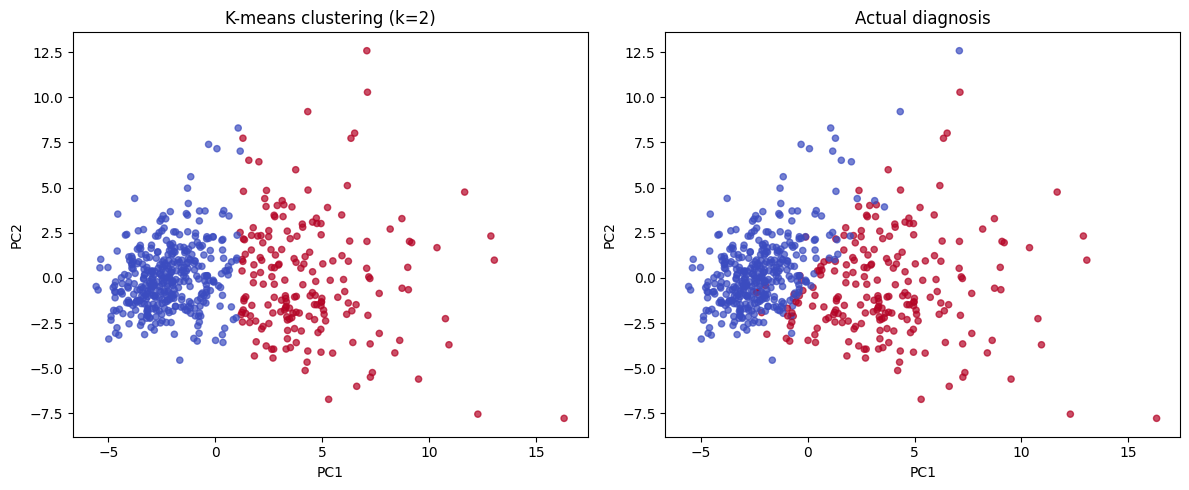

In [ ]:
#Fit K-means using two clusters

kmeans = KMeans(n_clusters=2, random_state=123, n_init=10)
clusters_kmeans = kmeans.fit_predict(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

#k-means clusters plot coloured by pca
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=clusters_kmeans, cmap="coolwarm", alpha=0.7, s=20, vmin=0, vmax=1)
axes[0].set_title("K-means clustering (k=2)")

#actual diagnosis
diagnosis = df_data.loc[X.index, "diagnosis"].map({"B": 0, "M": 1})

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=diagnosis, cmap="coolwarm", alpha=0.7, s=20, vmin=0, vmax=1)
axes[1].set_title("Actual diagnosis")

for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.tight_layout()
plt.show()

## Hierarchical clustering

Hierarchical clustering was used as a second clustering method.

Different linkage methods were compared before choosing a method for the final
clustering.

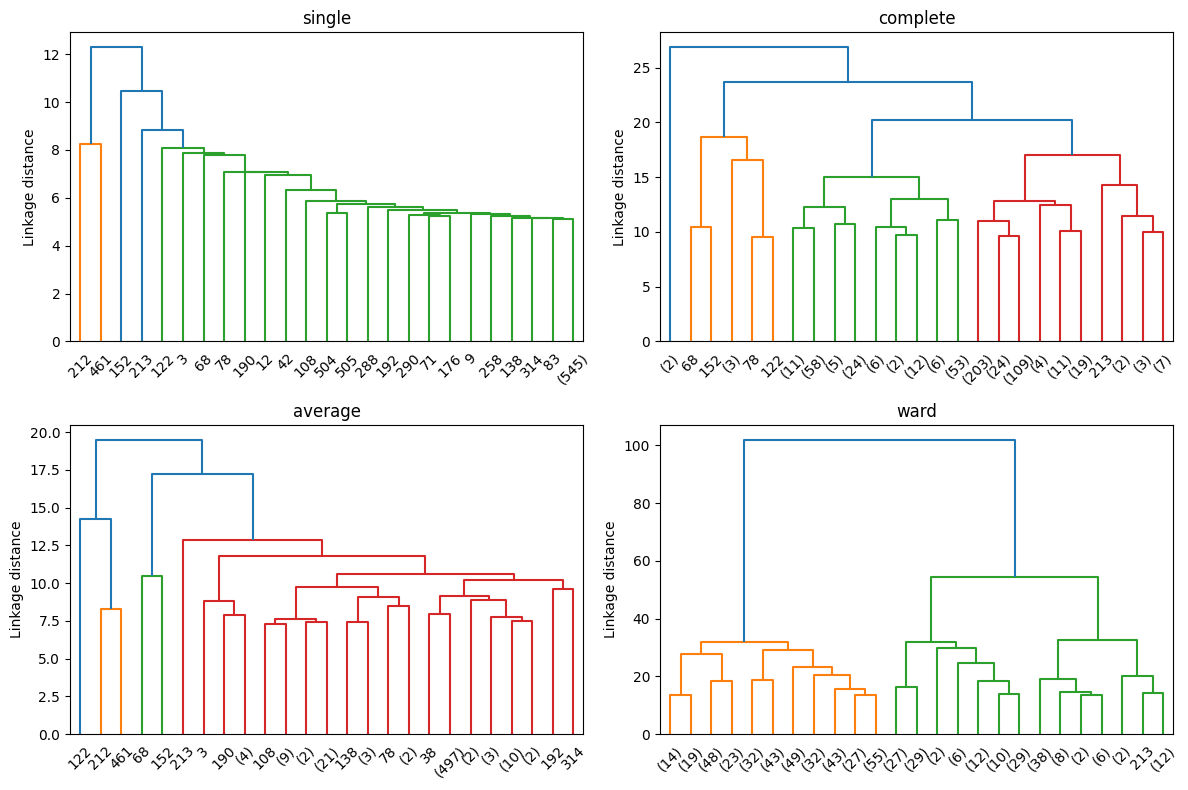

In [ ]:
#Compare four hierarchical clustering linkage methods
methods = ["single", "complete", "average", "ward"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, method in zip(axes.flat, methods):
    #Perform hierarchical clustering
    Z = linkage(X_scaled, method=method)

    dendrogram(Z, truncate_mode="lastp", p=25, ax=ax)
    ax.set_title(method)
    ax.set_ylabel("Linkage distance")

plt.tight_layout()
plt.show()

In [ ]:
#Use Ward linkage for the hierarchical clustering
Z_ward = linkage(X_scaled, method="ward")

#Cut the hierarchy into two clusters
clusters_hier = fcluster(
    Z_ward,
    t=2,
    criterion="maxclust")

print("Cluster sizes:")
print(pd.Series(clusters_hier).value_counts().sort_index())

Cluster sizes:
1    385
2    184
Name: count, dtype: int64


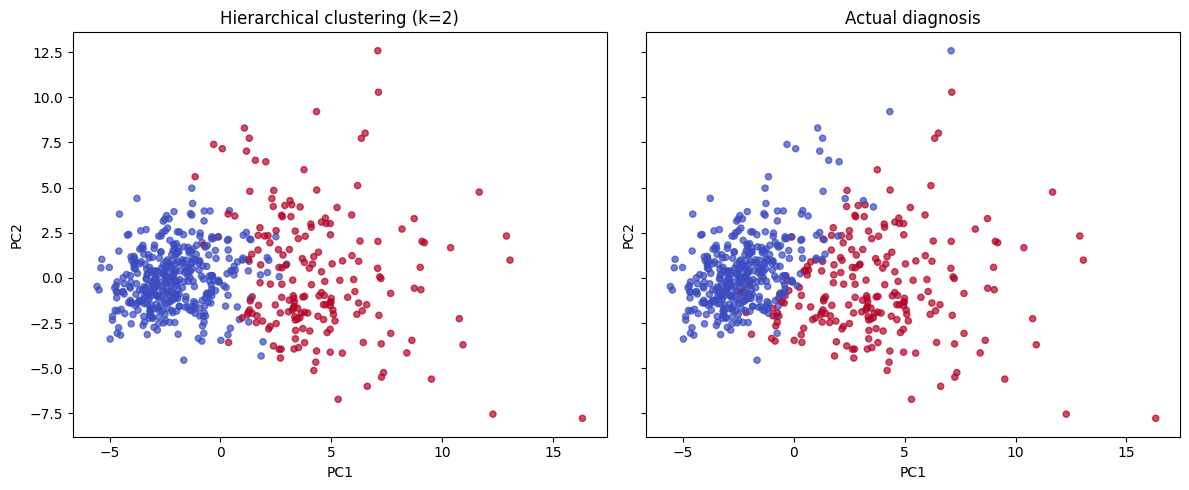

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

diagnosis = df_data.loc[X.index, "diagnosis"].map({"B": 0, "M": 1})

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=clusters_hier - 1, cmap="coolwarm", vmin=0, vmax=1, alpha=0.7, s=20)
axes[0].set_title("Hierarchical clustering (k=2)")

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=diagnosis, cmap="coolwarm", vmin=0, vmax=1, alpha=0.7, s=20)
axes[1].set_title("Actual diagnosis")

for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.tight_layout()
plt.show()

Ward linkage was used for the final clustering because it keeps the
variation within clusters small. The hierarchy was cut into two clusters so
that the result could be compared with K-means and the two known diagnoses.

In [ ]:
agreement = adjusted_rand_score(
    clusters_kmeans,
    clusters_hier)

print("ARI between K-means and hierarchical clustering:", agreement)

ARI between K-means and hierarchical clustering: 0.8163668665187986


In [ ]:
ari_kmeans = adjusted_rand_score(diagnosis, clusters_kmeans)

ari_hier = adjusted_rand_score(diagnosis,clusters_hier)

print("K-means ARI:", ari_kmeans)
print("Hierarchical ARI:", ari_hier)

K-means ARI: 0.6707206476880808
Hierarchical ARI: 0.5750409366326297


## Comparison of clustering methods

The Adjusted Rand Index (ARI) is used to compare the cluster assignments.
K-means and hierarchical clustering showed strong agreement with each other,
with an ARI of 0.816. This suggests that the two clustering methods identified a similar structure in the data.

K-means showed greater agreement with the known diagnosis (ARI = 0.671) than
hierarchical clustering (ARI = 0.575). However, neither method perfectly
reproduced the benign and malignant groups, showing that the natural clusters
in the feature data do not completely correspond to the known diagnoses.

## Method choice and limitations

### PCA

PCA was chosen because the dataset contains 30 numerical features describing
different characteristics of the cell nuclei. Many of these measurements are
related to each other, such as radius and area, so PCA is useful for reducing the number of dimensions while keeping as much of the variation in the data as possible.

PCA also makes it possible to visualize the observations using the first two
principal components instead of trying to visualize all 30 features at once.

However, PCA only captures linear combinations of the original features.
Nonlinear relationships between measurements may therefore be missed.
Additionally, PCA keeps directions with the greatest variation, but the
features that explain the most variation are not necessarily the features
that are most related to diagnosis.

### K-means clustering

K-means was chosen because all of the features used in the analysis are
numerical and the aim was to investigate whether the samples naturally form
groups without using the diagnosis labels.

The dataset has two known diagnoses, benign and malignant, so a two-cluster
solution can later be compared with these known groups. However, several
values of k were first compared using inertia and silhouette score rather than assuming that two clusters were automatically the best structure.

One limitation of K-means is that it works best when clusters are compact and well separated around their centers. The benign and malignant samples
may not have this type of structure and may overlap in the feature space.

### Hierarchical clustering

Hierarchical clustering was chosen as a second clustering method so that the
structure found by K-means could be compared with a method that does not begin
by assigning observations to fixed cluster centers.

The dataset is relatively small, which makes hierarchical clustering practical.
Different linkage methods were compared before Ward linkage was selected.
Ward linkage was suitable because it attempts to create groups with relatively
small variation within each cluster.

A limitation is that hierarchical clustering can produce different results
depending on the linkage method and distance measure used. It can also be sensitive to outliers because unusual observations can affect the distances used when clusters are merged.